# Temporal and operational post-analysis — Infiltration, original labels

Run in Colab **on CPU**, in order. Reuses predictions saved by the ablation analysis under `results_stgnn_spatial_ablation_v1/diagnostic_test2_spatial`. If that cache is missing, first run the three prediction and comparison cells that accompanied the ablation notebook. This notebook **does not train**. It runs inference once for any missing original baselines and saves their probabilities to Drive.

The **main** tables compare ST-GNN against Simple MLP, E-GraphSAGE, Static GNN, and Edge GRU using validation-selected champions. The **ablation** tables compare ST-GNN with ST Uniform and ST No Message.

Graphs are 30-second windows indexed by flow start time. Detection delay is measured retrospectively from the first attack-labeled flow. Graph attributes contain statistics of completed flows, so this delay is not an online alert latency. MITRE stages are not inferred.


## 1. Setup and provenance

In [1]:
import gc, hashlib, importlib.util, json, os, subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import average_precision_score, f1_score

if importlib.util.find_spec('torch_geometric') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'torch_geometric'], check=True)

from google.colab import drive
drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive/nids-mitre')
CODE_ROOT = Path('/content/temporalgnn-nids-st-ablation')
SOURCE_BRANCH = 'feat/fair-comparison-experiments'
SOURCE_COMMIT = '2262b53d155f9e8cf5221516f47e4170e6cd0d6e'
if not CODE_ROOT.exists():
    subprocess.run(['git', 'clone', '--depth', '1', '--branch', SOURCE_BRANCH,
                    'https://github.com/tatipar/temporalgnn-nids.git',
                    str(CODE_ROOT)], check=True)
subprocess.run(
    ['git', '-C', str(CODE_ROOT), 'fetch', '--depth', '1', 'origin', SOURCE_COMMIT],
    check=True,
)
subprocess.run(
    ['git', '-C', str(CODE_ROOT), 'checkout', '--detach', SOURCE_COMMIT],
    check=True,
)
actual_commit = subprocess.check_output(
    ['git', '-C', str(CODE_ROOT), 'rev-parse', 'HEAD'], text=True
).strip()
assert actual_commit == SOURCE_COMMIT, f'Code commit differs: {actual_commit}'
sys.path.insert(0, str(CODE_ROOT / 'code/python'))

from utils.datasets import NF_IDS_Dataset
from utils.models import EdgeGRU_Baseline_NoX, SimpleMLP, E_GraphSAGE, StaticGNN_Identity
from utils.metrics import calculate_metrics_gnn

DEVICE = torch.device('cpu')
GRAPH_ROOT = DRIVE_ROOT / 'dataset_processed_thu0103'
ORIGINAL_RESULTS = DRIVE_ROOT / 'results_earlystopping'
ABLATION_RESULTS = DRIVE_ROOT / 'results_stgnn_spatial_ablation_v1'
PRED_DIR = ABLATION_RESULTS / 'diagnostic_test2_spatial'
POST_DIR = DRIVE_ROOT / 'results_comparison' / 'temporal_operational_v1'
POST_DIR.mkdir(parents=True, exist_ok=True)
assert PRED_DIR.is_dir(), f'Missing saved predictions: {PRED_DIR}'

dataset = NF_IDS_Dataset(root_dir=str(GRAPH_ROOT), split='test2')
assert len(dataset) == 2822, f'Expected 2,822 windows; found: {len(dataset)}'
assert [int(p.split('_')[1].split('.')[0]) for p in dataset.files] == list(range(2822)), (
    'Window IDs are not consecutive starting at zero'
)
GRAPH_START = pd.Timestamp(dataset[0].timestamp)
print('CPU:', __import__('platform').processor() or 'see /proc/cpuinfo')
print('Code:', SOURCE_COMMIT)
print('Start of first window:', GRAPH_START)
print('Results:', POST_DIR)


Mounted at /content/drive
CPU: x86_64
Code: 2262b53d155f9e8cf5221516f47e4170e6cd0d6e
Start of first window: 2018-03-01 00:00:03.289000
Results: /content/drive/MyDrive/nids-mitre/results_comparison/temporal_operational_v1


## 2. Saved predictions and window alignment

In [2]:
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


VARIANT_CACHES = {
    'ST-GNN': ('st_gnn_seed_42.npz', 42, 0.8384, 0.7576),
    'ST Uniform': ('st_uniform_seed_42.npz', 42, 0.6883, 0.6256),
    'ST No Message': ('st_no_message_seed_2024.npz', 2024, 0.6601, 0.7115),
}
predictions = {}
for name, (filename, seed, expected_ap, expected_f1) in VARIANT_CACHES.items():
    path = PRED_DIR / filename
    assert path.is_file(), f'Missing {path}; run the ablation analysis first'
    with np.load(path, allow_pickle=False) as saved:
        labels = saved['labels'].astype(np.int8, copy=False)
        sources = saved['sources'].astype(np.int64, copy=False)
        probs = saved['probabilities'].astype(np.float32, copy=False)
        threshold = float(saved['threshold'])
        cached_sha256 = str(saved['checkpoint_sha256'].item())
    if name == 'ST-GNN':
        original_exp = 'ST_GNN_BiasOn_robust_Identity_clone'
        original_csv = ORIGINAL_RESULTS / 'test2_results' / f'test2_metrics_{original_exp}.csv'
        original_row = pd.read_csv(original_csv).iloc[0]
        assert int(original_row['seed']) == seed
        original_run_id = str(original_row['run_id'])
        matches = list((ORIGINAL_RESULTS / 'saved_models' / original_exp).glob(f'{original_run_id}_*.pth'))
        assert len(matches) == 1, matches
        assert cached_sha256 == sha256_file(matches[0])
        with np.load(ORIGINAL_RESULTS / 'logs' / original_exp / f'thresholds_{original_exp}.npz') as saved_thresholds:
            assert threshold == float(saved_thresholds[f'seed_{seed}'])
    else:
        stem = name.lower().replace(' ', '_')
        record_path = ABLATION_RESULTS / stem / f'seed_{seed}' / 'record.json'
        checkpoint_path = record_path.parent / 'checkpoint.pth'
        record = json.loads(record_path.read_text())
        assert record['source_commit'] == SOURCE_COMMIT
        assert record['checkpoint_sha256'] == cached_sha256 == sha256_file(checkpoint_path)
        assert float(record['threshold']) == threshold
    metrics = calculate_metrics_gnn(labels, probs, prob_threshold=threshold)
    assert len(labels) == 2_135_957 and int(labels.sum()) == 103_825
    assert np.isclose(metrics['AUC-PR'], expected_ap, atol=0.0002), (name, metrics['AUC-PR'])
    assert np.isclose(metrics['F1'], expected_f1, atol=0.0002), (name, metrics['F1'])
    predictions[name] = dict(labels=labels, sources=sources, probs=probs,
                             threshold=threshold, seed=seed)
    print(f'{name}: AP={metrics["AUC-PR"]:.4f}; F1={metrics["F1"]:.4f}; cache verified')

reference = predictions['ST-GNN']
for name, result in predictions.items():
    np.testing.assert_array_equal(result['labels'], reference['labels'])
    np.testing.assert_array_equal(result['sources'], reference['sources'])

# Read graphs only; do not rerun inference for the three preceding models.
window_cache = POST_DIR / 'window_ids_test2.npz'
label_digest = hashlib.sha256(reference['labels'].tobytes()).hexdigest()
source_digest = hashlib.sha256(reference['sources'].tobytes()).hexdigest()
if window_cache.exists():
    with np.load(window_cache, allow_pickle=False) as saved:
        assert str(saved['label_sha256'].item()) == label_digest
        assert str(saved['source_sha256'].item()) == source_digest
        windows = saved['windows'].astype(np.int32, copy=False)
    print('Window IDs loaded from Drive')
else:
    w_parts, y_parts, s_parts = [], [], []
    for window_id in range(len(dataset)):
        graph = dataset[window_id]
        if graph.x.shape[0] == 0:
            continue
        count = int(graph.y.numel())
        w_parts.append(np.full(count, window_id, dtype=np.int32))
        y_parts.append(graph.y.numpy().astype(np.int8))
        s_parts.append(graph.global_node_ids[graph.edge_index[0]].numpy().astype(np.int64))
        if (window_id + 1) % 500 == 0:
            print('Graphs read:', window_id + 1)
    windows = np.concatenate(w_parts)
    np.testing.assert_array_equal(np.concatenate(y_parts), reference['labels'])
    np.testing.assert_array_equal(np.concatenate(s_parts), reference['sources'])
    tmp_path = POST_DIR / 'window_ids_test2.tmp.npz'
    np.savez_compressed(tmp_path, windows=windows,
                        label_sha256=np.array(label_digest),
                        source_sha256=np.array(source_digest))
    os.replace(tmp_path, window_cache)
assert len(windows) == len(reference['labels'])
print('Windows aligned with flows:', len(windows))


ST-GNN: AP=0.8384; F1=0.7576; cache verified
ST Uniform: AP=0.6883; F1=0.6256; cache verified
ST No Message: AP=0.6601; F1=0.7115; cache verified
Window IDs loaded from Drive
Windows aligned with flows: 2135957


## 3. Original baselines: CPU inference without retraining

In [3]:
EDGE_EXP = 'EdgeGRU_NoX_BiasOn'
edge_csv = ORIGINAL_RESULTS / 'test2_results' / f'test2_metrics_{EDGE_EXP}.csv'
edge_row = pd.read_csv(edge_csv).iloc[0]
edge_seed = int(edge_row['seed'])
edge_run_id = str(edge_row['run_id'])
assert edge_seed == 99
edge_matches = list((ORIGINAL_RESULTS / 'saved_models' / EDGE_EXP).glob(f'{edge_run_id}_*.pth'))
assert len(edge_matches) == 1, edge_matches
edge_checkpoint = edge_matches[0]
edge_hash = sha256_file(edge_checkpoint)
with np.load(ORIGINAL_RESULTS / 'logs' / EDGE_EXP / f'thresholds_{EDGE_EXP}.npz') as saved:
    edge_threshold = float(saved[f'seed_{edge_seed}'])

edge_cache = POST_DIR / 'edge_gru_seed_99_test2.npz'
if edge_cache.exists():
    with np.load(edge_cache, allow_pickle=False) as saved:
        assert str(saved['checkpoint_sha256'].item()) == edge_hash
        assert float(saved['threshold']) == edge_threshold
        edge_labels = saved['labels'].astype(np.int8, copy=False)
        edge_sources = saved['sources'].astype(np.int64, copy=False)
        edge_probs = saved['probabilities'].astype(np.float32, copy=False)
    print('Edge GRU: predictions loaded from Drive')
else:
    model = EdgeGRU_Baseline_NoX(node_dim=16, edge_dim=32, hidden_dim=32,
                                 dropout=0.2, output_bias_init=-2.9968).to(DEVICE)
    state = torch.load(edge_checkpoint, map_location=DEVICE, weights_only=True)
    model.load_state_dict(state, strict=True)
    model.eval()
    model.reset_memory()
    y_parts, s_parts, p_parts = [], [], []
    with torch.no_grad():
        for window_id in range(len(dataset)):
            graph = dataset[window_id]
            if graph.x.shape[0] == 0:
                continue
            logits = model(graph.x, graph.edge_index, graph.edge_attr,
                           graph.global_node_ids).view(-1)
            y_parts.append(graph.y.numpy().astype(np.int8))
            s_parts.append(graph.global_node_ids[graph.edge_index[0]].numpy().astype(np.int64))
            p_parts.append(torch.sigmoid(logits).numpy().astype(np.float32))
            if (window_id + 1) % 500 == 0:
                print('Edge GRU: windows processed', window_id + 1)
    edge_labels = np.concatenate(y_parts)
    edge_sources = np.concatenate(s_parts)
    edge_probs = np.concatenate(p_parts)
    tmp_path = POST_DIR / 'edge_gru_seed_99_test2.tmp.npz'
    np.savez_compressed(tmp_path, labels=edge_labels, sources=edge_sources,
                        probabilities=edge_probs, threshold=np.array(edge_threshold),
                        checkpoint_sha256=np.array(edge_hash))
    os.replace(tmp_path, edge_cache)
    del model, state
    gc.collect()
    print('Edge GRU: predictions saved to Drive')

np.testing.assert_array_equal(edge_labels, reference['labels'])
np.testing.assert_array_equal(edge_sources, reference['sources'])
edge_metrics = calculate_metrics_gnn(edge_labels, edge_probs, prob_threshold=edge_threshold)
assert np.isclose(edge_metrics['AUC-PR'], 0.7307, atol=0.0002), edge_metrics['AUC-PR']
assert np.isclose(edge_metrics['F1'], 0.6502, atol=0.0002), edge_metrics['F1']
predictions['Edge GRU'] = dict(labels=edge_labels, sources=edge_sources, probs=edge_probs,
                               threshold=edge_threshold, seed=edge_seed)
print(f'Edge GRU reproduced: AP={edge_metrics["AUC-PR"]:.4f}; F1={edge_metrics["F1"]:.4f}')

BASE_PARAMS = dict(node_dim=16, edge_dim=32, hidden_dim=32,
                   dropout=0.2, output_bias_init=-2.9968)
BASELINE_SPECS = [
    ('Simple MLP', 'SimpleMLP_BiasOn', SimpleMLP, 777, 0.3961, 0.4722),
    ('E-GraphSAGE', 'EGraphSAGE_BiasOn', E_GraphSAGE, 99, 0.5050, 0.4950),
    ('Static GNN', 'StaticGNN_BiasOn_robust_Identity', StaticGNN_Identity, 42, 0.3142, 0.2944),
]
for name, experiment, model_class, expected_seed, expected_ap, expected_f1 in BASELINE_SPECS:
    reported_csv = ORIGINAL_RESULTS / 'test2_results' / f'test2_metrics_{experiment}.csv'
    reported = pd.read_csv(reported_csv).iloc[0]
    seed = int(reported['seed'])
    assert seed == expected_seed, (name, seed)
    run_id = str(reported['run_id'])
    matches = list((ORIGINAL_RESULTS / 'saved_models' / experiment).glob(f'{run_id}_*.pth'))
    assert len(matches) == 1, (name, matches)
    checkpoint = matches[0]
    checkpoint_hash = sha256_file(checkpoint)
    with np.load(ORIGINAL_RESULTS / 'logs' / experiment / f'thresholds_{experiment}.npz') as saved:
        threshold = float(saved[f'seed_{seed}'])

    cache = POST_DIR / f'{experiment}_seed_{seed}_test2.npz'
    if cache.exists():
        with np.load(cache, allow_pickle=False) as saved:
            assert str(saved['checkpoint_sha256'].item()) == checkpoint_hash
            assert float(saved['threshold']) == threshold
            labels_i = saved['labels'].astype(np.int8, copy=False)
            sources_i = saved['sources'].astype(np.int64, copy=False)
            probs_i = saved['probabilities'].astype(np.float32, copy=False)
        print(f'{name}: predictions loaded from Drive')
    else:
        model = model_class(**BASE_PARAMS).to(DEVICE)
        state = torch.load(checkpoint, map_location=DEVICE, weights_only=True)
        model.load_state_dict(state, strict=True)
        model.eval()
        y_parts, s_parts, p_parts = [], [], []
        with torch.no_grad():
            for window_id in range(len(dataset)):
                graph = dataset[window_id]
                if graph.x.shape[0] == 0:
                    continue
                logits = model(graph.x, graph.edge_index, graph.edge_attr).view(-1)
                y_parts.append(graph.y.numpy().astype(np.int8))
                s_parts.append(graph.global_node_ids[graph.edge_index[0]].numpy().astype(np.int64))
                p_parts.append(torch.sigmoid(logits).numpy().astype(np.float32))
                if (window_id + 1) % 500 == 0:
                    print(f'{name}: windows processed', window_id + 1)
        labels_i = np.concatenate(y_parts)
        sources_i = np.concatenate(s_parts)
        probs_i = np.concatenate(p_parts)
        tmp_path = POST_DIR / f'{experiment}_seed_{seed}_test2.tmp.npz'
        np.savez_compressed(tmp_path, labels=labels_i, sources=sources_i,
                            probabilities=probs_i, threshold=np.array(threshold),
                            checkpoint_sha256=np.array(checkpoint_hash))
        os.replace(tmp_path, cache)
        del model, state
        gc.collect()
        print(f'{name}: predictions saved to Drive')

    np.testing.assert_array_equal(labels_i, reference['labels'])
    np.testing.assert_array_equal(sources_i, reference['sources'])
    metrics_i = calculate_metrics_gnn(labels_i, probs_i, prob_threshold=threshold)
    assert np.isclose(metrics_i['AUC-PR'], expected_ap, atol=0.0002), (name, metrics_i['AUC-PR'])
    assert np.isclose(metrics_i['F1'], expected_f1, atol=0.0002), (name, metrics_i['F1'])
    predictions[name] = dict(labels=labels_i, sources=sources_i, probs=probs_i,
                             threshold=threshold, seed=seed)
    print(f'{name} reproduced: AP={metrics_i["AUC-PR"]:.4f}; F1={metrics_i["F1"]:.4f}')

PRIMARY_MODELS = ['Simple MLP', 'E-GraphSAGE', 'Static GNN', 'Edge GRU', 'ST-GNN']
ABLATION_MODELS = ['ST-GNN', 'ST Uniform', 'ST No Message']
assert set(predictions) == set(PRIMARY_MODELS) | set(ABLATION_MODELS)

metric_rows = []
for name, result in predictions.items():
    scores = calculate_metrics_gnn(result['labels'], result['probs'],
                                   prob_threshold=result['threshold'])
    metric_rows.append({'model': name, 'seed': result['seed'],
                        'AP': scores['AUC-PR'], 'F1': scores['F1'],
                        'precision': scores['Precision'], 'recall': scores['Recall'],
                        'FPR': scores['FPR'], 'TP': scores['TP'], 'FP': scores['FP']})
metric_table = pd.DataFrame(metric_rows)
for title, model_names, suffix in [
    ('Main comparison: flow metrics, Test 2', PRIMARY_MODELS, 'baselines'),
    ('Ablations: flow metrics, Test 2', ABLATION_MODELS, 'ablations'),
]:
    print(title)
    selected = metric_table.set_index('model').loc[model_names].reset_index()
    selected.to_csv(POST_DIR / f'flow_metrics_{suffix}.csv', index=False)
    display(selected.round(4))


Edge GRU: predictions loaded from Drive
Edge GRU reproduced: AP=0.7307; F1=0.6502
Simple MLP: predictions loaded from Drive
Simple MLP reproduced: AP=0.3961; F1=0.4722
E-GraphSAGE: predictions loaded from Drive
E-GraphSAGE reproduced: AP=0.5050; F1=0.4950
Static GNN: predictions loaded from Drive
Static GNN reproduced: AP=0.3142; F1=0.2944
Main comparison: flow metrics, Test 2


,model,seed,AP,F1,precision,recall,FPR,TP,FP
0,Simple MLP,777,0.3961,0.4722,0.8805,0.3226,0.0022,33492,4547
1,E-GraphSAGE,99,0.5050,0.4950,0.5787,0.4324,0.0161,44891,32677
2,Static GNN,42,0.3142,0.2944,0.5094,0.2071,0.0102,21497,20707
3,Edge GRU,99,0.7307,0.6502,0.5990,0.7110,0.0243,73819,49410
4,ST-GNN,42,0.8384,0.7576,0.6336,0.9419,0.0278,97793,56546


Ablations: flow metrics, Test 2


,model,seed,AP,F1,precision,recall,FPR,TP,FP
0,ST-GNN,42,0.8384,0.7576,0.6336,0.9419,0.0278,97793,56546
1,ST Uniform,42,0.6883,0.6256,0.5660,0.6993,0.0274,72609,55676
2,ST No Message,2024,0.6601,0.7115,0.7610,0.6681,0.0107,69362,21788


## 4. First detection and continuity

The analysis unit is an **attacked source in Test 2**. A hit is an alert on an attack-labeled flow. Delay is measured from that source's first window with an attack label. Sources never receiving a true positive have censored delay and are counted separately. Incidents and attack stages are not reconstructed.


In [4]:
labels = reference['labels']
sources = reference['sources']
attacked_sources = np.unique(sources[labels == 1])


def longest_consecutive_missed(active_windows, hit_windows):
    hits = set(int(w) for w in hit_windows)
    longest = current = 0
    previous = None
    for raw_window in active_windows:
        window = int(raw_window)
        if window in hits:
            current = 0
        else:
            current = current + 1 if previous is not None and window == previous + 1 else 1
            longest = max(longest, current)
        previous = window
    return longest


source_rows = []
for name, result in predictions.items():
    alert = result['probs'] > result['threshold']  # original decision operator
    attack = labels == 1
    relevant = pd.DataFrame({
        'source': sources[attack],
        'window': windows[attack],
        'hit': alert[attack],
    })
    for source, group in relevant.groupby('source', sort=True):
        active = np.sort(group['window'].unique())
        hits = np.sort(group.loc[group['hit'], 'window'].unique())
        first_hit = int(hits[0]) if len(hits) else None
        delay = (first_hit - int(active[0])) if first_hit is not None else None
        before_first = int((active < first_hit).sum()) if first_hit is not None else len(active)
        after_first = int((active >= first_hit).sum()) if first_hit is not None else 0
        source_rows.append({
            'model': name,
            'source_gid': int(source),
            'attack_flows': len(group),
            'attack_windows': len(active),
            'first_attack_window': int(active[0]),
            'first_hit_window': first_hit,
            'detected': first_hit is not None,
            'delay_windows': delay,
            'nominal_delay_minutes': (delay * 0.5 if delay is not None else np.nan),
            'attack_windows_detected': len(hits),
            'attack_window_coverage': len(hits) / len(active),
            'attack_windows_before_first_hit': before_first,
            'coverage_after_first_hit': len(hits) / after_first if after_first else np.nan,
            'longest_consecutive_missed_windows': longest_consecutive_missed(active, hits),
        })

source_table = pd.DataFrame(source_rows)
assert source_table.groupby('model').size().eq(len(attacked_sources)).all()
source_table.to_csv(POST_DIR / 'source_detection.csv', index=False)

summary_rows = []
for subset_name, included in [
    ('All attacked sources', source_table['source_gid'] >= 0),
    ('Excluding source 1195', source_table['source_gid'] != 1195),
]:
    for name, group in source_table[included].groupby('model'):
        detected = group['detected']
        delay = group['nominal_delay_minutes']
        summary_rows.append({
            'subset': subset_name,
            'model': name,
            'attacked_sources': len(group),
            'sources_detected': int(detected.sum()),
            'sources_never_detected': int((~detected).sum()),
            'median_minutes_detected_only': delay.median(),
            'detected_in_first_window': int((group['delay_windows'] == 0).sum()),
            'detected_within_5_min': int((delay <= 5).sum()),
            'detected_within_30_min': int((delay <= 30).sum()),
            'mean_source_coverage': group['attack_window_coverage'].mean(),
            'window_weighted_coverage': group['attack_windows_detected'].sum() / group['attack_windows'].sum(),
            'median_longest_miss_streak': group['longest_consecutive_missed_windows'].median(),
        })

summary = pd.DataFrame(summary_rows)
summary.to_csv(POST_DIR / 'source_temporal_summary.csv', index=False)
for title, model_names, suffix in [
    ('Main comparison: ST-GNN and baselines', PRIMARY_MODELS, 'baselines'),
    ('Ablations: ST-GNN and variants', ABLATION_MODELS, 'ablations'),
]:
    print(title)
    selected = summary[summary.model.isin(model_names)]
    selected.to_csv(POST_DIR / f'temporal_summary_{suffix}.csv', index=False)
    display(selected.round(3))
    print('Source 1195:')
    display(source_table[(source_table.source_gid == 1195) &
                         source_table.model.isin(model_names)].round(3))

# Median delay above is conditional on source detection.
# This breakdown checks whether source coverage depends on sources with
# very few attack-labeled flows.
source_table['attack_count_group'] = pd.cut(
    source_table['attack_flows'], bins=[0, 1, 9, 49, np.inf],
    labels=['1', '2-9', '10-49', '50+']
)
support_rows = []
for (name, group_name), group in source_table.groupby(['model', 'attack_count_group'], observed=True):
    support_rows.append({
        'model': name,
        'attack_flows_per_source': str(group_name),
        'sources': len(group),
        'detected': int(group['detected'].sum()),
        'fraction_detected': group['detected'].mean(),
        'mean_window_coverage': group['attack_window_coverage'].mean(),
    })
support_table = pd.DataFrame(support_rows)
support_table.to_csv(POST_DIR / 'source_support_detection.csv', index=False)
for title, model_names, suffix in [
    ('Baselines: coverage by source attack count', PRIMARY_MODELS, 'baselines'),
    ('Ablations: coverage by source attack count', ABLATION_MODELS, 'ablations'),
]:
    print(title)
    selected = support_table[support_table.model.isin(model_names)]
    selected.to_csv(POST_DIR / f'support_detection_{suffix}.csv', index=False)
    display(selected.round(3))


Main comparison: ST-GNN and baselines


,subset,model,attacked_sources,sources_detected,sources_never_detected,median_minutes_detected_only,detected_in_first_window,detected_within_5_min,detected_within_30_min,mean_source_coverage,window_weighted_coverage,median_longest_miss_streak
0,All attacked sources,E-GraphSAGE,380,58,322,0.0,48,48,53,0.116,0.351,1.0
1,All attacked sources,Edge GRU,380,113,267,0.0,96,102,108,0.246,0.810,1.0
4,All attacked sources,ST-GNN,380,141,239,0.0,100,110,121,0.309,0.828,1.0
5,All attacked sources,Simple MLP,380,49,331,0.0,44,44,46,0.115,0.025,1.0
6,All attacked sources,Static GNN,380,31,349,0.0,18,18,23,0.040,0.312,1.0
7,Excluding source 1195,E-GraphSAGE,379,57,322,0.0,48,48,53,0.115,0.351,1.0
8,Excluding source 1195,Edge GRU,379,112,267,0.0,96,102,108,0.245,0.824,1.0
11,Excluding source 1195,ST-GNN,379,140,239,0.0,100,110,121,0.308,0.843,1.0
12,Excluding source 1195,Simple MLP,379,48,331,0.0,44,44,46,0.115,0.010,1.0
13,Excluding source 1195,Static GNN,379,30,349,0.0,18,18,23,0.039,0.309,1.0


Source 1195:


,model,source_gid,attack_flows,attack_windows,first_attack_window,first_hit_window,detected,delay_windows,nominal_delay_minutes,attack_windows_detected,attack_window_coverage,attack_windows_before_first_hit,coverage_after_first_hit,longest_consecutive_missed_windows
54,ST-GNN,1195,36934,229,1473,1700.0,True,227.0,113.5,104,0.454,107,0.852,13
1194,Edge GRU,1195,36934,229,1473,1667.0,True,194.0,97.0,109,0.476,85,0.757,12
1574,Simple MLP,1195,36934,229,1473,1702.0,True,229.0,114.5,91,0.397,109,0.758,15
1954,E-GraphSAGE,1195,36934,229,1473,1702.0,True,229.0,114.5,80,0.349,109,0.667,15
2334,Static GNN,1195,36934,229,1473,1702.0,True,229.0,114.5,89,0.389,109,0.742,15


Ablations: ST-GNN and variants


...

,model,source_gid,attack_flows,attack_windows,first_attack_window,first_hit_window,detected,delay_windows,nominal_delay_minutes,attack_windows_detected,attack_window_coverage,attack_windows_before_first_hit,coverage_after_first_hit,longest_consecutive_missed_windows
54,ST-GNN,1195,36934,229,1473,1700.0,True,227.0,113.5,104,0.454,107,0.852,13
434,ST Uniform,1195,36934,229,1473,1700.0,True,227.0,113.5,87,0.380,107,0.713,13
814,ST No Message,1195,36934,229,1473,1762.0,True,289.0,144.5,49,0.214,163,0.742,65


Baselines: coverage by source attack count


,model,attack_flows_per_source,sources,detected,fraction_detected,mean_window_coverage
0,E-GraphSAGE,1,25,1,0.040,0.040
1,E-GraphSAGE,2-9,304,38,0.125,0.116
2,E-GraphSAGE,10-49,31,4,0.129,0.022
3,E-GraphSAGE,50+,20,15,0.750,0.350
4,Edge GRU,1,25,5,0.200,0.200
5,Edge GRU,2-9,304,69,0.227,0.210
6,Edge GRU,10-49,31,19,0.613,0.265
7,Edge GRU,50+,20,20,1.000,0.826
16,ST-GNN,1,25,6,0.240,0.240
17,ST-GNN,2-9,304,90,0.296,0.267


Ablations: coverage by source attack count


,model,attack_flows_per_source,sources,detected,fraction_detected,mean_window_coverage
8,ST No Message,1,25,5,0.200,0.200
9,ST No Message,2-9,304,63,0.207,0.173
10,ST No Message,10-49,31,23,0.742,0.410
11,ST No Message,50+,20,20,1.000,0.750
12,ST Uniform,1,25,7,0.280,0.280
13,ST Uniform,2-9,304,136,0.447,0.416
14,ST Uniform,10-49,31,25,0.806,0.484
15,ST Uniform,50+,20,20,1.000,0.808
16,ST-GNN,1,25,6,0.240,0.240
17,ST-GNN,2-9,304,90,0.296,0.267


In [5]:
import numpy as np
from scipy.stats import binomtest

paired = (
    source_table[source_table["model"].isin(["ST-GNN", "Edge GRU"])]
    .pivot(index="source_gid", columns="model", values="detected")
    .astype(bool)
)
assert len(paired) == 380
assert paired.notna().all().all()

st = paired["ST-GNN"].to_numpy()
edge = paired["Edge GRU"].to_numpy()

only_st = int((st & ~edge).sum())
only_edge = int((~st & edge).sum())
both = int((st & edge).sum())
none = int((~st & ~edge).sum())

# Paired difference in the proportion of detected sources.
difference = st.astype(int) - edge.astype(int)
rng = np.random.default_rng(2026)
indices = rng.integers(0, len(difference), size=(5000, len(difference)))
ic95 = np.quantile(difference[indices].mean(axis=1), [0.025, 0.975])

# The exact McNemar test is equivalent to a binomial test on the discordant pairs.
discordant = only_st + only_edge
p_exact = (
    binomtest(only_st, discordant, p=0.5).pvalue
    if discordant else 1.0
)

print(f"Both detect: {both}")
print(f"Only ST-GNN: {only_st}")
print(f"Only Edge GRU: {only_edge}")
print(f"None detect: {none}")
print(f"Coverage difference: {difference.mean():+.3%}")
print(f"Exploratory 95% CI by source: [{ic95[0]:+.3%}, {ic95[1]:+.3%}]")
print(f"Exact McNemar, p = {p_exact:.4g}")

Both detect: 84
Only ST-GNN: 57
Only Edge GRU: 29
None detect: 210
Coverage difference: +7.368%
Exploratory 95% CI by source: [+2.895%, +12.105%]
Exact McNemar, p = 0.003353


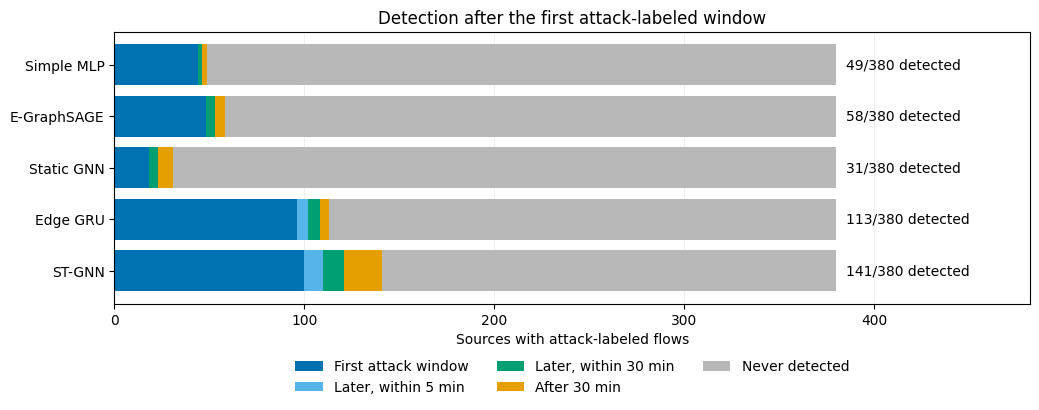

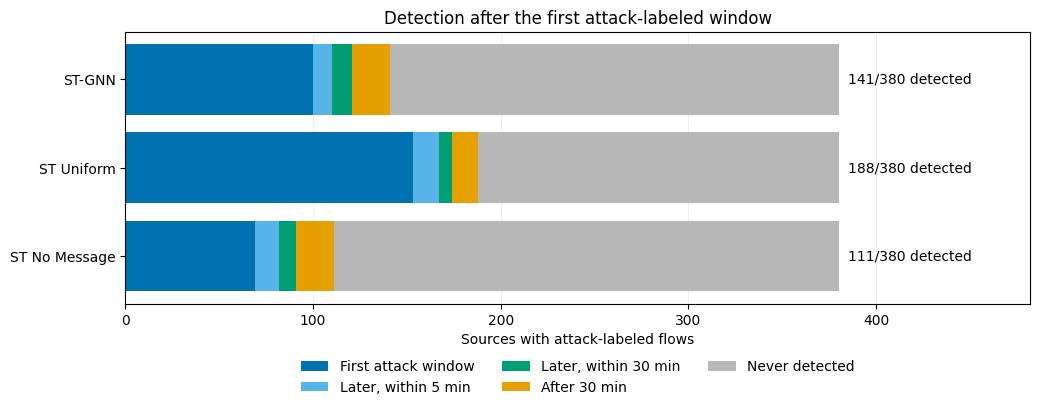

In [12]:
import matplotlib.pyplot as plt

def save_postanalysis_figure(fig, name):
    fig.savefig(POST_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(POST_DIR / f"{name}.png", dpi=300, bbox_inches="tight")

detection_groups = [
    "First attack window",
    "Later, within 5 min",
    "Later, within 30 min",
    "After 30 min",
    "Never detected",
]
group_colors = {
    "First attack window": "#0072B2",
    "Later, within 5 min": "#56B4E9",
    "Later, within 30 min": "#009E73",
    "After 30 min": "#E69F00",
    "Never detected": "#B8B8B8",
}

plot_sources = source_table.copy()
detected = plot_sources["detected"].astype(bool)
delay = plot_sources["nominal_delay_minutes"]

plot_sources["detection_group"] = np.select(
    [
        detected & delay.eq(0),
        detected & delay.gt(0) & delay.le(5),
        detected & delay.gt(5) & delay.le(30),
        detected & delay.gt(30),
    ],
    detection_groups[:-1],
    default="Never detected",
)
assert not (
    detected & plot_sources["detection_group"].eq("Never detected")
).any()

for figure_name, model_names in [
    ("source_detection_timing_baselines", PRIMARY_MODELS),
    ("source_detection_timing_ablations", ABLATION_MODELS),
]:
    counts = (
        plot_sources[plot_sources["model"].isin(model_names)]
        .groupby(["model", "detection_group"])
        .size()
        .unstack(fill_value=0)
        .reindex(index=model_names, columns=detection_groups, fill_value=0)
    )

    fig, ax = plt.subplots(figsize=(10.5, 4.3))
    positions = np.arange(len(model_names))
    left = np.zeros(len(model_names), dtype=int)

    for group in detection_groups:
        values = counts[group].to_numpy()
        ax.barh(
            positions, values, left=left,
            color=group_colors[group], label=group,
        )
        left += values

    for position, model in enumerate(model_names):
        total = int(counts.loc[model].sum())
        hits = total - int(counts.loc[model, "Never detected"])
        ax.text(total + 5, position, f"{hits}/{total} detected", va="center")

    ax.set_yticks(positions, model_names)
    ax.invert_yaxis()
    ax.set_xlim(0, int(counts.sum(axis=1).max() * 1.27))
    ax.set_xlabel("Sources with attack-labeled flows")
    ax.set_title("Detection after the first attack-labeled window")
    ax.legend(
        frameon=False, ncol=3,
        loc="upper center", bbox_to_anchor=(0.5, -0.16),
    )
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    fig.tight_layout()
    save_postanalysis_figure(fig, figure_name)
    plt.show()

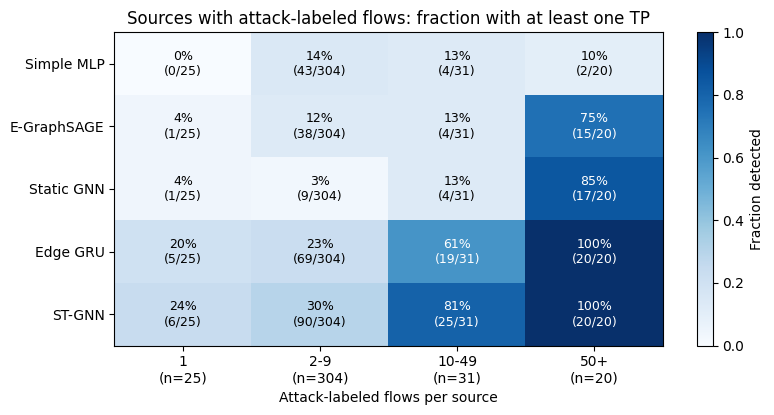

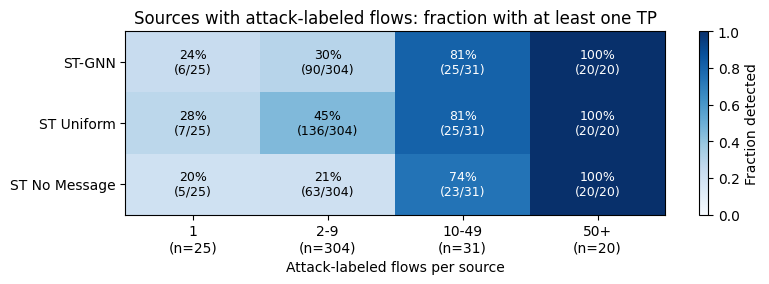

In [13]:
attack_groups = ["1", "2-9", "10-49", "50+"]
support_lookup = support_table.set_index(
    ["model", "attack_flows_per_source"]
)

group_sizes = {
    group: int(support_lookup.loc[("ST-GNN", group), "sources"])
    for group in attack_groups
}

for figure_name, model_names in [
    ("source_detection_by_attack_count_baselines", PRIMARY_MODELS),
    ("source_detection_by_attack_count_ablations", ABLATION_MODELS),
]:
    values = np.array([
        [
            float(support_lookup.loc[(model, group), "fraction_detected"])
            for group in attack_groups
        ]
        for model in model_names
    ])

    fig, ax = plt.subplots(figsize=(8.2, 1.0 + 0.65 * len(model_names)))
    image = ax.imshow(
        values, cmap="Blues", vmin=0, vmax=1, aspect="auto"
    )

    for row, model in enumerate(model_names):
        for col, group in enumerate(attack_groups):
            record = support_lookup.loc[(model, group)]
            detected_count = int(record["detected"])
            source_count = int(record["sources"])
            assert source_count == group_sizes[group]

            fraction = float(record["fraction_detected"])
            ax.text(
                col, row,
                f"{fraction:.0%}\n({detected_count}/{source_count})",
                ha="center", va="center",
                color="white" if fraction >= 0.55 else "black",
                fontsize=9,
            )

    ax.set_xticks(
        range(len(attack_groups)),
        [f"{group}\n(n={group_sizes[group]})" for group in attack_groups],
    )
    ax.set_yticks(range(len(model_names)), model_names)
    ax.set_xlabel("Attack-labeled flows per source")
    ax.set_title("Sources with attack-labeled flows: fraction with at least one TP")
    fig.colorbar(image, ax=ax, label="Fraction detected")

    fig.tight_layout()
    save_postanalysis_figure(fig, figure_name)
    plt.show()


## 5. CPU alert workload: flows and source-window pairs

Each model keeps its validation-selected threshold. A source-window pair containing any attack-labeled flow is an attack window. The analysis separates alerts with a true positive, alerts with no labeled attack, and alerts on benign flows in an attack window that contain no true positive. Counts depend on the original labels.


In [6]:
base_pairs = pd.DataFrame({
    'window': windows,
    'source': sources,
    'attack': labels == 1,
})
attack_pairs = base_pairs.loc[base_pairs.attack, ['window', 'source']].drop_duplicates()
attack_pairs['window_contains_attack'] = True
N_HOURS = (len(dataset) + 119) // 120  # 120 thirty-second windows per hour

workload_rows = []
hourly_rows = []
for name, result in predictions.items():
    alert = result['probs'] > result['threshold']
    alert_df = pd.DataFrame({
        'window': windows[alert],
        'source': sources[alert],
        'attack': labels[alert] == 1,
    })
    groups = alert_df.groupby(['window', 'source'], sort=False).agg(
        alerted_flows=('attack', 'size'),
        has_true_positive=('attack', 'any'),
    ).reset_index()
    groups = groups.merge(attack_pairs, on=['window', 'source'], how='left', validate='one_to_one')
    groups['window_contains_attack'] = groups['window_contains_attack'].eq(True)
    groups['false_source_window'] = ~groups['window_contains_attack']
    groups['only_benign_alert_in_attack_window'] = (
        groups['window_contains_attack'] & ~groups['has_true_positive']
    )
    workload_rows.append({
        'model': name,
        'alerted_flows': int(alert.sum()),
        'FP_flows': int((alert & (labels == 0)).sum()),
        'alerted_source_window_pairs': len(groups),
        'pairs_with_true_positive': int(groups['has_true_positive'].sum()),
        'pairs_without_labeled_attack': int(groups['false_source_window'].sum()),
        'attack_pairs_with_only_benign_alerts': int(groups['only_benign_alert_in_attack_window'].sum()),
    })

    flow_hours = pd.DataFrame({
        'hour': windows[alert] // 120,
        'FP': labels[alert] == 0,
    }).groupby('hour').agg(flow_alerts=('FP', 'size'), FP_flows=('FP', 'sum'))
    group_hours = groups.assign(hour=groups['window'] // 120).groupby('hour').agg(
        source_window_alerts=('source', 'size'),
        source_window_alerts_without_attack=('false_source_window', 'sum'),
    )
    hours = flow_hours.join(group_hours, how='outer').reindex(range(N_HOURS), fill_value=0).fillna(0)
    for hour, row in hours.iterrows():
        hourly_rows.append({'model': name, 'hour_since_start': int(hour),
                            **{column: int(value) for column, value in row.items()}})

workload = pd.DataFrame(workload_rows)
hourly = pd.DataFrame(hourly_rows)
workload.to_csv(POST_DIR / 'alert_workload.csv', index=False)
hourly.to_csv(POST_DIR / 'hourly_alert_workload.csv', index=False)
def p95(values):
    return values.quantile(0.95)

for title, model_names, suffix in [
    ('Main comparison: ST-GNN and baselines', PRIMARY_MODELS, 'baselines'),
    ('Ablations: ST-GNN and variants', ABLATION_MODELS, 'ablations'),
]:
    print(title)
    selected_workload = workload[workload.model.isin(model_names)]
    selected_hourly = hourly[hourly.model.isin(model_names)]
    selected_workload.to_csv(POST_DIR / f'alert_workload_{suffix}.csv', index=False)
    selected_hourly.to_csv(POST_DIR / f'hourly_alert_workload_{suffix}.csv', index=False)
    display(selected_workload)
    display(selected_hourly.groupby('model')[[
        'flow_alerts', 'FP_flows', 'source_window_alerts',
        'source_window_alerts_without_attack'
    ]].agg(['median', p95, 'max']).round(1))
print('Medians may be zero when many hours have no alerts; inspect p95 and maximum as well.')
print('The final hour may be partial; the hourly table retains each interval.')


Main comparison: ST-GNN and baselines


,model,alerted_flows,FP_flows,alerted_source_window_pairs,pairs_with_true_positive,pairs_without_labeled_attack,attack_pairs_with_only_benign_alerts
0,ST-GNN,154339,56546,8081,4877,3162,42
3,Edge GRU,123229,49410,8090,4771,3257,62
4,Simple MLP,38039,4547,746,150,596,0
5,E-GraphSAGE,77568,32677,5284,2066,3170,48
6,Static GNN,42204,20707,3983,1838,2117,28


flow_alerts                 FP_flows                  \
                 median      p95    max   median      p95    max   
model                                                              
E-GraphSAGE         2.0  10860.1  21676      2.0   4765.3   5715   
Edge GRU            0.0  24732.7  40573      0.0   9119.1  16730   
ST-GNN              0.0  33096.2  51755      0.0  12429.6  15923   
Simple MLP          0.5   7676.8  23484      0.5    996.2   2329   
Static GNN          0.0   5686.2   7569      0.0   2876.1   4507   

            source_window_alerts                \
                          median     p95   max   
model                                            
E-GraphSAGE                  1.0   751.2   820   
Edge GRU                     0.0  1434.0  1576   
ST-GNN                       0.0  1279.6  1654   
Simple MLP                   0.5   138.7   183   
Static GNN                   0.0   611.4   804   

            source_window_alerts_without_attack              
                                         median    p95  max  
model                                                        
E-GraphSAGE                                 1.0  439.6  507  
Edge GRU                                    0.0  536.0  619  
ST-GNN                                      0.0  500.7  572  
Simple MLP                                  0.5  104.7  146  
Static GNN                                  0.0  325.4  514

Ablations: ST-GNN and variants


,model,alerted_flows,FP_flows,alerted_source_window_pairs,pairs_with_true_positive,pairs_without_labeled_attack,attack_pairs_with_only_benign_alerts
0,ST-GNN,154339,56546,8081,4877,3162,42
1,ST Uniform,128285,55676,7577,5049,2486,42
2,ST No Message,91150,21788,5943,4480,1345,118


flow_alerts                 FP_flows                  \
                   median      p95    max   median      p95    max   
model                                                                
ST No Message         0.5  20842.8  27889      0.5   5435.1   6010   
ST Uniform            0.5  26911.7  35688      0.5  12342.4  16529   
ST-GNN                0.0  33096.2  51755      0.0  12429.6  15923   

              source_window_alerts                \
                            median     p95   max   
model                                              
ST No Message                  0.5  1134.9  1420   
ST Uniform                     0.5  1429.2  1861   
ST-GNN                         0.0  1279.6  1654   

              source_window_alerts_without_attack              
                                           median    p95  max  
model                                                          
ST No Message                                 0.5  314.2  437  
ST Uniform                                    0.5  546.2  750  
ST-GNN                                        0.0  500.7  572

Medians may be zero when many hours have no alerts; inspect p95 and maximum as well.
The final hour may be partial; the hourly table retains each interval.


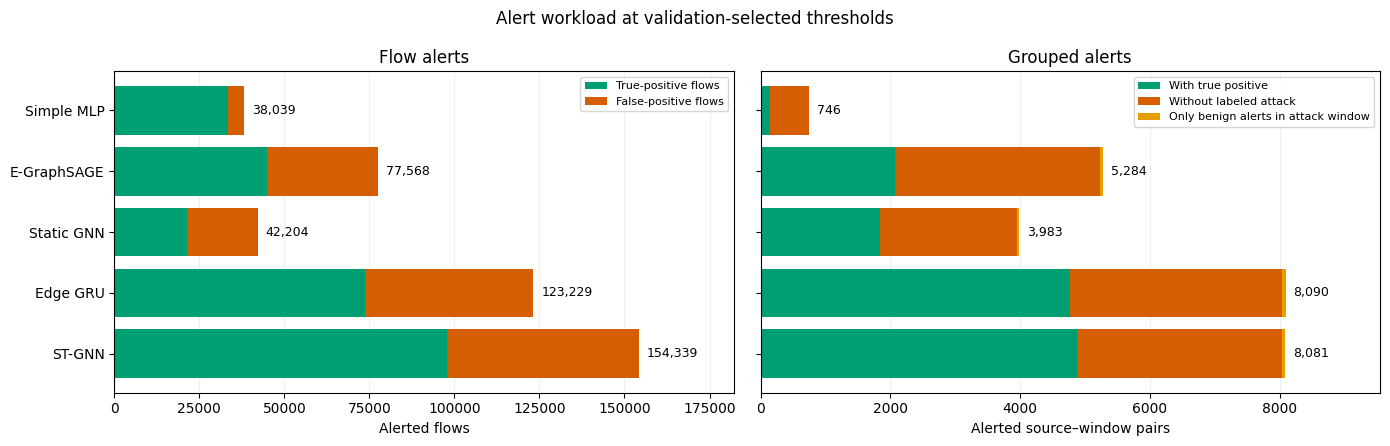

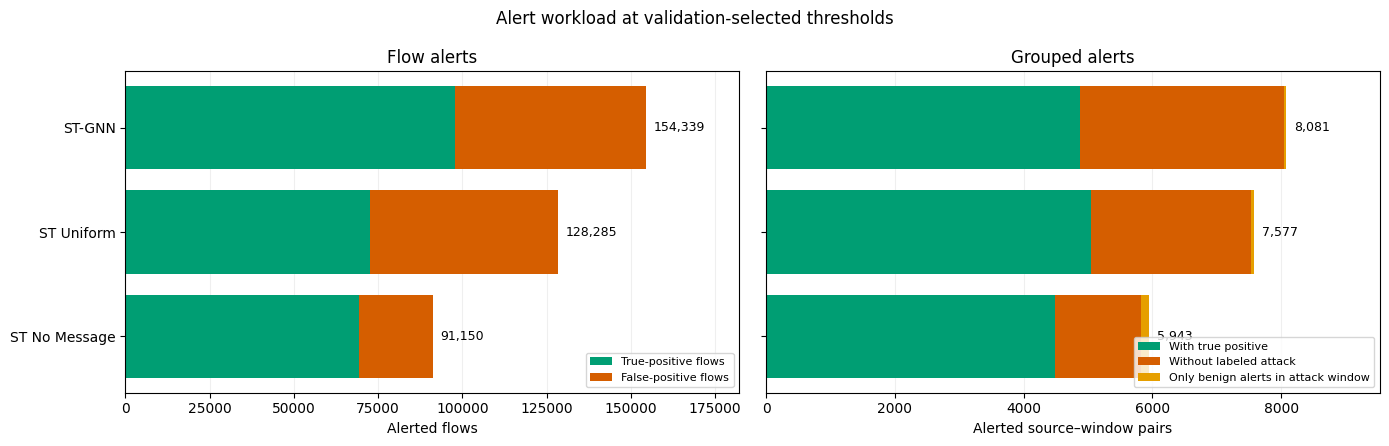

In [18]:
for figure_name, model_names in [
    ("alert_workload_baselines", PRIMARY_MODELS),
    ("alert_workload_ablations", ABLATION_MODELS),
]:
    table = workload.set_index("model").loc[model_names]
    positions = np.arange(len(model_names))

    true_positive_flows = (
        table["alerted_flows"] - table["FP_flows"]
    ).to_numpy()
    false_positive_flows = table["FP_flows"].to_numpy()

    pair_parts = [
        ("With true positive", "pairs_with_true_positive", "#009E73"),
        ("Without labeled attack", "pairs_without_labeled_attack", "#D55E00"),
        (
            "Only benign alerts in attack window",
            "attack_pairs_with_only_benign_alerts",
            "#E69F00",
        ),
    ]

    assert (
        table[[column for _, column, _ in pair_parts]].sum(axis=1)
        == table["alerted_source_window_pairs"]
    ).all()

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)

    axes[0].barh(
        positions, true_positive_flows,
        color="#009E73", label="True-positive flows",
    )
    axes[0].barh(
        positions, false_positive_flows,
        left=true_positive_flows,
        color="#D55E00", label="False-positive flows",
    )

    legend_location = (
        "upper right"
        if figure_name == "alert_workload_baselines"
        else "lower right"
    )

    pair_left = np.zeros(len(model_names), dtype=int)
    for label, column, color in pair_parts:
        values = table[column].to_numpy()
        axes[1].barh(
            positions, values, left=pair_left,
            color=color, label=label,
        )
        pair_left += values

    for ax, totals in [
        (axes[0], table["alerted_flows"].to_numpy()),
        (axes[1], table["alerted_source_window_pairs"].to_numpy()),
    ]:
        ax.set_xlim(0, int(totals.max() * 1.18))
        ax.grid(axis="x", alpha=0.2)
        ax.set_axisbelow(True)
        for position, total in enumerate(totals):
            ax.text(
                total + totals.max() * 0.015,
                position,
                f"{int(total):,}",
                va="center",
                fontsize=9,
            )

    axes[0].set_yticks(positions, model_names)
    axes[0].invert_yaxis()
    axes[0].set_title("Flow alerts")
    axes[0].set_xlabel("Alerted flows")
    axes[0].legend(frameon=True, fontsize=8, loc=legend_location)

    axes[1].set_title("Grouped alerts")
    axes[1].set_xlabel("Alerted source–window pairs")
    axes[1].legend(frameon=True, fontsize=8, loc=legend_location)

    fig.suptitle("Alert workload at validation-selected thresholds")
    fig.tight_layout()
    save_postanalysis_figure(fig, figure_name)
    plt.show()

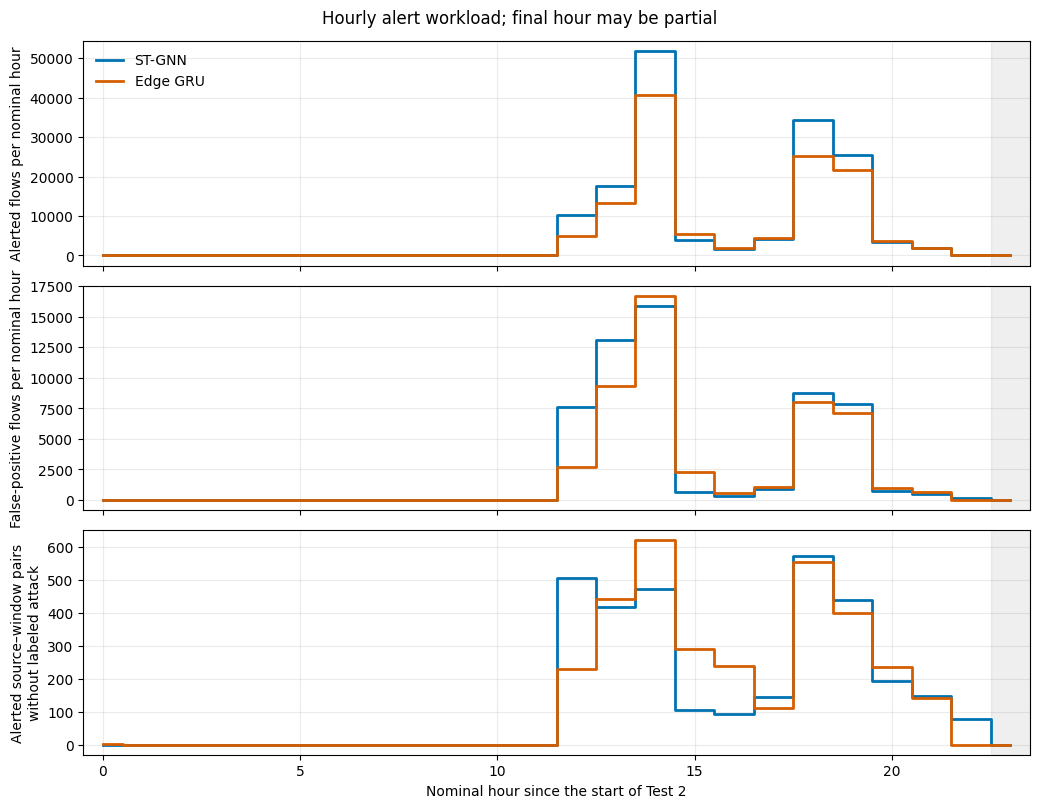

In [19]:
hourly_models = ["ST-GNN", "Edge GRU"]
hourly_colors = {
    "ST-GNN": "#0072B2",
    "Edge GRU": "#D55E00",
}

hourly_panels = [
    ("flow_alerts", "Alerted flows per nominal hour"),
    ("FP_flows", "False-positive flows per nominal hour"),
    (
        "source_window_alerts_without_attack",
        "Alerted source–window pairs\nwithout labeled attack",
    ),
]

fig, axes = plt.subplots(3, 1, figsize=(10.5, 8.2), sharex=True)

for ax, (column, ylabel) in zip(axes, hourly_panels):
    for model in hourly_models:
        rows = (
            hourly[hourly["model"] == model]
            .sort_values("hour_since_start")
        )
        ax.plot(
            rows["hour_since_start"],
            rows[column],
            label=model,
            color=hourly_colors[model],
            linewidth=2,
            drawstyle="steps-mid",
        )

    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.set_axisbelow(True)

last_hour = int(hourly["hour_since_start"].max())
for ax in axes:
    ax.axvspan(
        last_hour - 0.5,
        last_hour + 0.5,
        color="gray",
        alpha=0.12,
    )
    ax.set_xlim(-0.5, last_hour + 0.5)

axes[0].legend(frameon=False)
axes[-1].set_xlabel("Nominal hour since the start of Test 2")

fig.suptitle("Hourly alert workload; final hour may be partial")
fig.tight_layout()

save_postanalysis_figure(
    fig, "hourly_alert_workload_st_vs_edge_three_panels"
)
plt.show()

## 6. Availability audit for completed-flow attributes

This audit reads the original CSV in chunks and counts flows whose duration exceeds the time remaining until the end of their start window. This **suggests** that their complete statistics would not be available at that window boundary. It does not estimate exporter delay or turn this experiment into an online deployment.


In [7]:
RAW_CSV = DRIVE_ROOT / 'data/cicids2018-v3/cicids2018v3_thu0103.csv'
if not RAW_CSV.is_file():
    print('Original CSV not found; skipping this audit:', RAW_CSV)
else:
    columns = ['FLOW_START_TIME', 'FLOW_DURATION_MILLISECONDS',
               'IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'Attack']
    graph_rows = valid_duration_rows = crossed_rows = attack_rows = crossed_attack_rows = 0
    invalid_duration_rows = 0
    all_durations = []
    for chunk_no, chunk in enumerate(pd.read_csv(RAW_CSV, usecols=columns, chunksize=250_000), start=1):
        valid_ip = ((chunk['IPV4_SRC_ADDR'] != '0.0.0.0') &
                    (chunk['IPV4_DST_ADDR'] != '0.0.0.0'))
        chunk = chunk.loc[valid_ip]
        graph_rows += len(chunk)
        starts = pd.to_datetime(chunk['FLOW_START_TIME'], errors='coerce')
        durations = pd.to_numeric(chunk['FLOW_DURATION_MILLISECONDS'], errors='coerce')
        valid = starts.notna() & np.isfinite(durations) & (durations >= 0)
        invalid_duration_rows += int((~valid).sum())
        starts, durations = starts[valid], durations[valid]
        attacks = chunk.loc[valid, 'Attack'].eq('Infilteration')
        valid_duration_rows += len(starts)
        attack_rows += int(attacks.sum())
        offset_ms = (starts - GRAPH_START).dt.total_seconds().to_numpy() * 1000.0
        assert np.all(offset_ms >= 0), 'Some flows precede the start of the graphs'
        remaining_ms = 30_000.0 - np.mod(offset_ms, 30_000.0)
        cross = durations.to_numpy() > remaining_ms
        crossed_rows += int(cross.sum())
        crossed_attack_rows += int((cross & attacks.to_numpy()).sum())
        all_durations.append(durations.to_numpy(dtype=np.float64))
        print(f'Chunk {chunk_no}: {len(chunk)} flows with valid IPs')

    assert graph_rows == len(labels), (graph_rows, len(labels))
    duration_array = np.concatenate(all_durations)
    timing_audit = pd.DataFrame([{
        'flows_in_graphs': graph_rows,
        'flows_with_valid_duration': valid_duration_rows,
        'invalid_duration_count': invalid_duration_rows,
        'median_duration_ms': float(np.median(duration_array)),
        'p95_duration_ms': float(np.percentile(duration_array, 95)),
        'cross_start_window_end': crossed_rows,
        'fraction_cross_start_window_end': crossed_rows / valid_duration_rows,
        'attacks_with_valid_duration': attack_rows,
        'attacks_cross_start_window_end': crossed_attack_rows,
        'fraction_attacks_cross': crossed_attack_rows / attack_rows if attack_rows else np.nan,
    }])
    timing_audit.to_csv(POST_DIR / 'flow_availability_audit.csv', index=False)
    display(timing_audit.round(4))


Chunk 1: 248507 flows with valid IPs
Chunk 2: 248570 flows with valid IPs
Chunk 3: 248759 flows with valid IPs
Chunk 4: 248633 flows with valid IPs
Chunk 5: 248360 flows with valid IPs
Chunk 6: 248854 flows with valid IPs
Chunk 7: 248921 flows with valid IPs
Chunk 8: 248785 flows with valid IPs
Chunk 9: 146568 flows with valid IPs


,flows_in_graphs,flows_with_valid_duration,invalid_duration_count,median_duration_ms,p95_duration_ms,cross_start_window_end,fraction_cross_start_window_end,attacks_with_valid_duration,attacks_cross_start_window_end,fraction_attacks_cross
0,2135957,2135957,0,67.0,116522.0,349067,0.1634,103825,6383,0.0615


## Interpretation and scope

- Baseline tables are the paper's main comparison. Ablation tables describe changes to ST-GNN; by themselves they neither replace baselines nor establish causality.
- Nominal delay in minutes equals the window difference times 0.5. It refers to graphs indexed by flow start time. Never-detected sources remain in `sources_never_detected`.
- `window_weighted_coverage` counts each attack window for each source; `mean_source_coverage` gives each source equal weight.
- `pairs_without_labeled_attack` measures alerts grouped by source and window using original labels. Mixed groups with alerts only on benign flows are reported separately.
- Report the CPU model from the Colab output. Timing in the comparative notebook measures only `forward` calls on prebuilt graphs; this notebook does not present those times as end-to-end latency.
